# MMM01 Parameter Optimisation

Searches 210 configurations across static and IBM-offset markets, using 20 trials per configuration. The saved output contains the completed 4,200-session search and a separate Welch test against a reference grid configuration. Running either code cell repeats market simulations.


Total combinations: 210
Total simulation runs: 4200


100%|██████████| 210/210 [03:38<00:00,  1.04s/it]



Data preview:
   n_past  bid_pct  ask_delta  market  avg_profit
0       5      0.1         10  Static         0.0
1       5      0.1         10    Real         0.0
2       5      0.1         20  Static         0.0
3       5      0.1         20    Real         0.0
4       5      0.1         30  Static         0.0

Best n_past (Static): 20
Best n_past (Real): 20


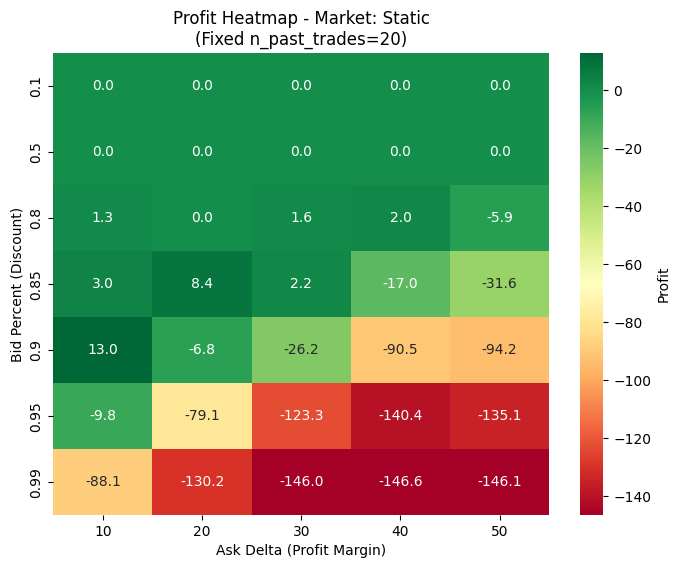

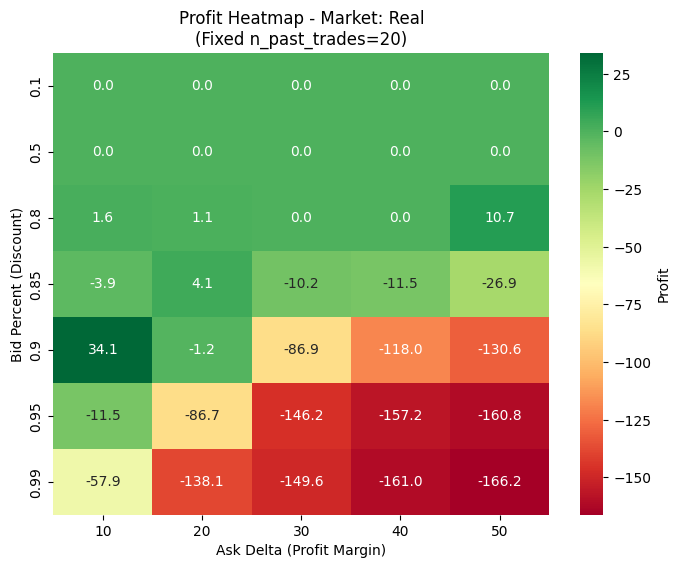

Market A (Static) best config:
 n_past           10
bid_pct         0.9
ask_delta        10
avg_profit    15.35
Name: 110, dtype: object

Market B (Real/IBM) best config:
 n_past           20
bid_pct         0.9
ask_delta        10
avg_profit    34.15
Name: 181, dtype: object

Final recommendation (MMM01*): n=20, bid=0.9, delta=10
Reference grid configuration profit: 0.00
Optimized profit: 34.15
Percentage improvement is not defined because the reference profit is zero.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from tqdm import tqdm  
import concurrent.futures
import market_maker_grid_search
import importlib

# Reload the helper module when working interactively.
importlib.reload(market_maker_grid_search)

# Parameter grid.

n_list = [5, 10, 20]             
bid_list = [0.1, 0.5, 0.8, 0.85, 0.9, 0.95, 0.99] 
delta_list = [10, 20, 30, 40, 50]   
market_types = ['Static', 'Real']      
N_TRIALS = 20  # Trials per configuration.

tasks = []
for n in n_list:
    for bid in bid_list:
        for delta in delta_list:
            for m_type in market_types:
                tasks.append((n, bid, delta, m_type, N_TRIALS))

print(f"Total combinations: {len(tasks)}")
print(f"Total simulation runs: {len(tasks) * N_TRIALS}")

# Run independent configurations in parallel.
results = []
if __name__ == '__main__':
    # Use separate processes for independent configurations.
    with concurrent.futures.ProcessPoolExecutor() as executor:
        # Track completed configurations.
        results = list(tqdm(executor.map(market_maker_grid_search.run_sim, tasks), total=len(tasks)))

df = pd.DataFrame(results, columns=['n_past', 'bid_pct', 'ask_delta', 'market', 'avg_profit'])

print("\nData preview:")
print(df.head())

# Find the strongest value of n_past for each market.
best_n_s = df[df['market']=='Static'].groupby('n_past')['avg_profit'].mean().idxmax()
best_n_r = df[df['market']=='Real'].groupby('n_past')['avg_profit'].mean().idxmax()

print(f"\nBest n_past (Static): {best_n_s}")
print(f"Best n_past (Real): {best_n_r}")

# Plot the parameter surface.
def show_heatmap(dataframe, market, n_val):
    subset = dataframe[(dataframe['market'] == market) & (dataframe['n_past'] == n_val)]
    
    # Place bid_pct on the heatmap's vertical axis.
    pivot = subset.pivot(index='bid_pct', columns='ask_delta', values='avg_profit')
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(pivot, annot=True, fmt=".1f", cmap="RdYlGn", cbar_kws={'label': 'Profit'})
    plt.title(f"Profit Heatmap - Market: {market}\n(Fixed n_past_trades={n_val})")
    plt.xlabel("Ask Delta (Profit Margin)")
    plt.ylabel("Bid Percent (Discount)")
    plt.show()

show_heatmap(df, 'Static', best_n_s)
show_heatmap(df, 'Real', best_n_r)

# Select the highest-profit configuration in each market.
best_config_s = df[df['market']=='Static'].sort_values('avg_profit', ascending=False).iloc[0]
best_config_r = df[df['market']=='Real'].sort_values('avg_profit', ascending=False).iloc[0]

print("Market A (Static) best config:\n", best_config_s[['n_past', 'bid_pct', 'ask_delta', 'avg_profit']])
print("\nMarket B (Real/IBM) best config:\n", best_config_r[['n_past', 'bid_pct', 'ask_delta', 'avg_profit']])

# Use the IBM-offset result as the final MMM01* configuration.
final_n = int(best_config_r['n_past'])
final_bid = float(best_config_r['bid_pct'])
final_delta = int(best_config_r['ask_delta'])

print(f"\nFinal recommendation (MMM01*): n={final_n}, bid={final_bid}, delta={final_delta}")

# Reference grid configuration.
reference_run = df[(df['n_past']==5) & (df['bid_pct']==0.5) & (df['ask_delta']==30) & (df['market']=='Real')]
# Improvement percentage
reference_profit = reference_run.iloc[0]['avg_profit']
best_profit = best_config_r['avg_profit']
print(f"Reference grid configuration profit: {reference_profit:.2f}")
print(f"Optimized profit: {best_profit:.2f}")
if reference_profit == 0:
    print("Percentage improvement is not defined because the reference profit is zero.")
else:
    print(f"Improvement: {((best_profit - reference_profit)/reference_profit)*100:.1f}%")

In [ ]:
import bse
import numpy as np
import os
from scipy import stats

csv_file = os.path.join('data', 'ibm_price_offsets.csv')
start_time = 0
end_time = 900

def get_profit_distribution(n_past, bid_pct, ask_delt, market_type, n_trials=20):
    '''Return trial profits for one parameter configuration.'''
    # Use the same market configuration as the grid-search helper.
    mm_params = {'n_past_trades': n_past, 'bid_percent': bid_pct, 'ask_delta': ask_delt}
    sellers = [('ZIP', 5), ('ZIC', 5), ('GVWY', 5), ('SHVR', 3)]
    buyers =  [('ZIP', 5), ('ZIC', 5), ('GVWY', 5), ('SHVR', 3)]
    traders = {'sellers': sellers, 'buyers': buyers, 'mrktmakers': [('MMM01', 1, mm_params)]}
    

    range_min, range_max = 100, 200
    if market_type == 'Real':
        # IBM-offset market configuration.
        offset_events = bse.schedule_offsetfn_read_file(csv_file, col_t=1, col_p=5, scale_factor=50)
        offset = (bse.schedule_offsetfn_from_eventlist, [ [end_time, offset_events] ])
        sup_range = [range_min, range_max, offset]
        dem_range = [range_min, range_max, offset]
    else:
        # Static market configuration.
        sup_range = [range_min, range_max]
        dem_range = [range_min, range_max]

    sup_sched = [{'from': 0, 'to': end_time, 'ranges': [sup_range], 'stepmode': 'fixed'}]
    dem_sched = [{'from': 0, 'to': end_time, 'ranges': [dem_range], 'stepmode': 'fixed'}]
    order_sched = {'sup': sup_sched, 'dem': dem_sched, 'interval': 30, 'timemode': 'drip-poisson'}
    
    dump_flags = {'dump_blotters': False, 'dump_lobs': False, 'dump_strats': False, 
                  'dump_avgbals': False, 'dump_tape': False}

    raw_profits = []
    for i in range(n_trials):
        trial_id = f"ttest_{market_type}_{i}"
        balances = bse.market_session(trial_id, start_time, end_time, traders, order_sched, dump_flags, False)
        profit = balances.get('M00', 0) - 500
        raw_profits.append(profit)
        
    return np.array(raw_profits)

# Reference grid configuration: n=5, bid=0.5, delta=30.
reference_profits = get_profit_distribution(n_past=5, bid_pct=0.5, ask_delt=30, market_type='Real')

# Optimised configuration: n=20, bid=0.9, delta=10.
optimized_profits = get_profit_distribution(n_past=20, bid_pct=0.9, ask_delt=10, market_type='Real')

# Welch's unequal-variance t-test.
t_stat, p_val = stats.ttest_ind(optimized_profits, reference_profits, equal_var=False)

print(f"\nHypothesis Testing Results: ")
print(f"Reference grid mean:   {reference_profits.mean():.2f} (Std: {reference_profits.std():.2f})")
print(f"Optimized config mean: {optimized_profits.mean():.2f} (Std: {optimized_profits.std():.2f})")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value:     {p_val:.4e}")  

if p_val < 0.05:
    print("Result: statistically significant (Reject H0)")
else:
    print("Result: not significant (Fail to reject H0)")


Hypothesis Testing Results: 
Reference grid mean:   0.00 (Std: 0.00)
Optimized config mean: 34.70 (Std: 42.90)
T-statistic: 3.5260
P-value:     2.2580e-03
Result: statistically significant (Reject H0)
